# Quantum Metal iSWAP example 2 — two pocket transmons and a flux-tunable coupler (Quantcore PDK rebuild)

**What the chip is.** Example 2 of the Qiskit Metal notebook
`docs/circuit-examples/F.Small-quantum-chips/Full-Physical-Design-of-iSWAP-Gates.ipynb` (after Phys. Rev. Research
2, 033447 (2020), Fig. 1, structure only; © IBM / Qiskit Metal contributors, Apache-2.0,
<https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/iswap2_pocket_tc.md`): two large
`TransmonPocket6` qubits (1 × 0.4 mm pads, 1.5 × 1.2 mm pockets, mm scale) 8 mm apart, with a `TunableCoupler02`
between them (two 300 µm-radius pads on a bus line that runs through a SQUID, and a flux-bias stub). Straight lines
join each qubit's inner connection pad to the coupler's bus ends; each qubit's outer pad has a 10 mm meandered line
to a launchpad, and the coupler's flux stub a line to a third launchpad. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal example 2 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 16 × 6 mm centred at (0, 1) mm | the same 16 × 6 mm box (it does not fit the 7.5 mm die), with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | three `LaunchpadWirebond`s 0.69 mm in from the edges | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge their pads face (south, south, east) |
| junctions | Metal junction lines (no inductance given; 10 nH assumed) | Quantcore trilayer junctions: PDK nominal for the qubits, a PDK SQUID for the coupler |
| coupler pocket | computed but never added (degenerate) | a 3.8 × 2 mm `metal:Rectangle` pocket (lead decision, option b) |
| cheese | none (the notebook never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RouteStraight`, `RouteMeander` (10 mm), a framed flux line | qcc `cpw` routes on Metal's own corner points (lengths kept; the pad leads grow with the pad rule) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options and relative positions, every route's end pins and
Metal's route corner points (route1 / route2 `RouteStraight` with their 5 µm leads and the 50 µm step between the
qubit and coupler pins; route3's 0.2 mm end lead, fillet 90 µm; route4 / route5 `RouteMeander` 10 mm, 200 µm pitch,
fillet 90 µm). All lines 10 / 6 µm (the tutorial sets `cpw_width = 0.01mm`; Metal's gap). Pin names as in the source
(route2 joins Q2's `readout` pad to the coupler, route5 Q2's `bus_03` pad to its launchpad).

**Substituted (lead decision, option b): the coupler's pocket.** `TunableCoupler02` draws metal only: Metal computes
a pocket but never adds it (and the computed one is degenerate: `draw.rectangle(0, 0, pocket_width, pocket_height)`
is a 0 × 0 box at (3, 2) mm, the arguments being width, height, x, y). Built exactly, the coupler is ground plane and
Q1 / Q2 are not coupled. It gets a `metal:Rectangle` with `subtract: true`, **3.8 × 2 mm centred on the coupler**:
Metal's `pocket_height` (2 mm), and pin to pin wide (its `pocket_width`, 3 mm, would leave the last 0.4 mm of each
bus arm, and so the coupler, shorted to the ground plane). The three coupler pins then sit on the pocket edge.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM → FEM job
→ results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
CPW = dict(a=10, b=6)                            # the tutorial's cpw_width = 0.01mm, Metal's cpw_gap

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 16 × 6 mm box gets the QCT frame; the three launchpads go 100 µm from the edges they face; the qubits get the PDK nominal trilayer junction and the coupler a PDK SQUID; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die (µm) and the PDK draws the **QCT frame** on it (L
dicing markers 1000/0, 3 × 3 alignment grids 1001/0, chip boundary 100/0, device ID `name_chip` on a free edge). The
design does not fit the 7.5 mm die, so the box is the source's 16 × 6 mm chip. Metal centres it at (0, 1) mm, so a
Metal position (x, y) is `P(x, y)` = (8000 + x, 2000 + y) here.

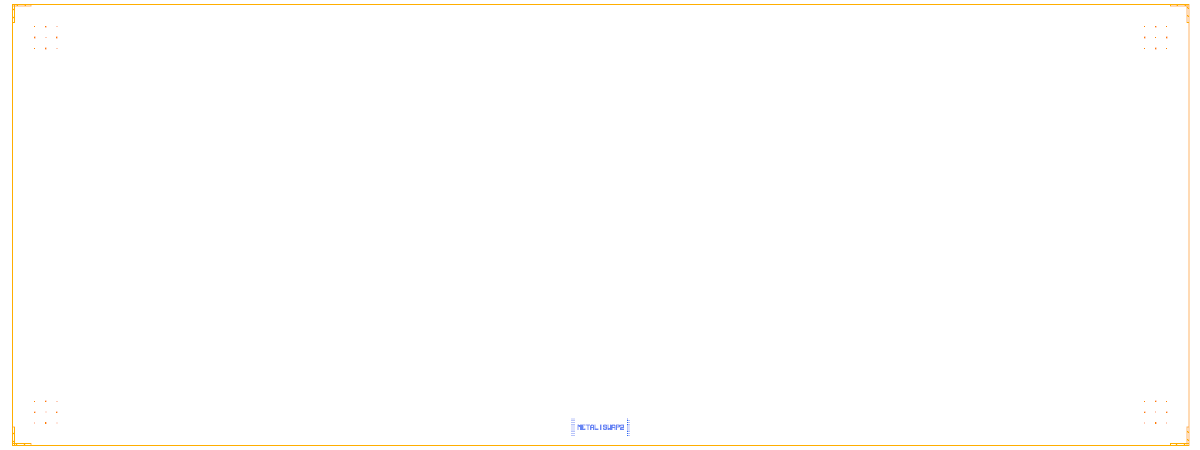

WindowsPath('examples/designs/metal/iswap2_pocket_tc_step_die.png')

In [4]:
d = Designer("iswap2_pocket_tc", box=(0, 0, 16000, 6000), chip={"name_chip": "MetalISWAP2"}, live=LIVE)
X0, Y0 = 8000, 2000                              # Metal's 16 × 6 mm chip is centred at (0, 1) mm
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
PP = lambda pts: [P(x, y) for x, y in pts]
rebuild(d)
snap(d, OUT / "iswap2_pocket_tc_step_die.png", size=(1200, 450), width=480)

## 4 · Pads: the PDK pad rule

The tutorial's three `LaunchpadWirebond`s (0.5 × 1 mm pads, no lead) sit 0.69 mm inside the chip: `P1_C` and `P2_C`
at the ends of the two 10 mm lines with their pads pointing **south**, `P3_C` at the end of the coupler's flux line
with its pad pointing **east**. In the Quantcore PDK the outer edge of every bond pad's etch sits **one dicing-marker
width (25 µm) from the die edge**: `edge="s"` / `"e"` slides each pad perpendicular to the edge it faces until it is
there, keeping its position along that edge. (`"auto"` would take the *nearest* edge, the west / north one, which
the pads do not face.) The lines are routed to the pads' ties later, so they simply get longer leads.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

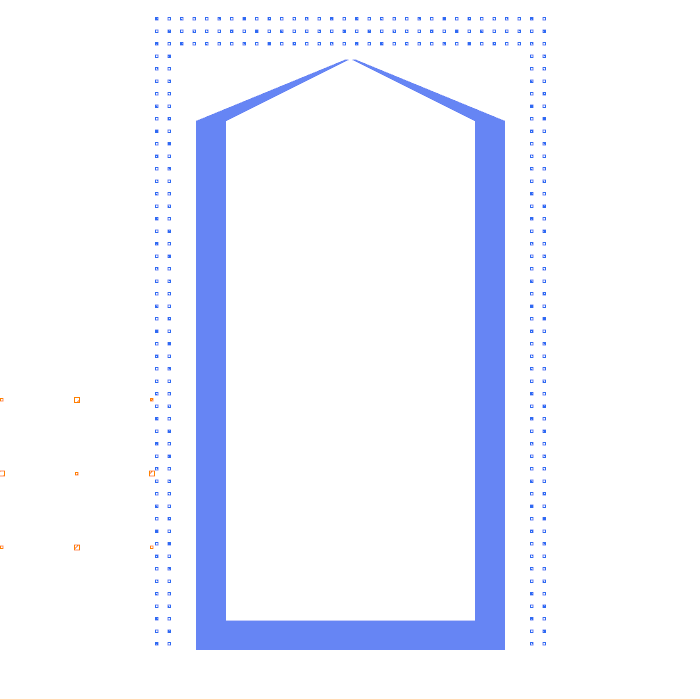

WindowsPath('examples/designs/metal/iswap2_pocket_tc_step_pads.png')

In [5]:
with d.batch():
    lp = {n: d.add(n, "metal:LaunchpadWirebond", at=P(x, y), rot=r, edge=e, pad_width="0.5mm", pad_height="1mm",
                   lead_length="0um")
          for n, x, y, r, e in (("P1_C", -7000, 500, 90, "s"), ("P2_C", 7000, 500, 90, "s"),
                                ("P3_C", 3000, 3000, -180, "e"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "P1_C.tie")
snap(d, OUT / "iswap2_pocket_tc_step_pads.png", box=(px - 700, 0, px + 700, 1400), size=(700, 700), width=300)

## 5 · Components: two pocket qubits and the tunable coupler

**The qubits.** `metal:TransmonPocket6` with the tutorial's options: 1 × 0.4 mm pads, a 1.5 × 1.2 mm pocket, rotated
90°, two connection pads `bus_03` (inner side of Q1) and `readout`. Their junction is the PDK's: the tutorial gives
no target and no inductance, so each gets the PDK nominal trilayer junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0
spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); `junction=` carries L_J and C_J to the LOM
and the FEM junction port. With the mm-scale pads the estimate is f_q ≈ 4.3 GHz (the assumed 10 nH gave 3.67 GHz,
below the PDK band).

**The coupler.** `metal:TunableCoupler02` (a series SQUID in a bus line, two 300 µm pads, a flux stub `fbl`) gets a
PDK SQUID: two 0.25 × 0.6 µm junctions, 45 kΩ in parallel, L_J 6.73 nH at zero flux. Its **pocket** (a
`metal:Rectangle` with `subtract: true`, 3.8 × 2 mm) is the substitution explained above: without it the coupler is
ground plane.

Each component has named ports (Metal's pins); routes connect to them and the LOM maps each to a circuit node.

qubits: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0} | coupler: {'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 6.7344}} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['bus_03', 'readout', 'squid_a', 'squid_b'] | TC ports: ['fbl', 'pin1', 'pin2', 'squid_a', 'squid_b']


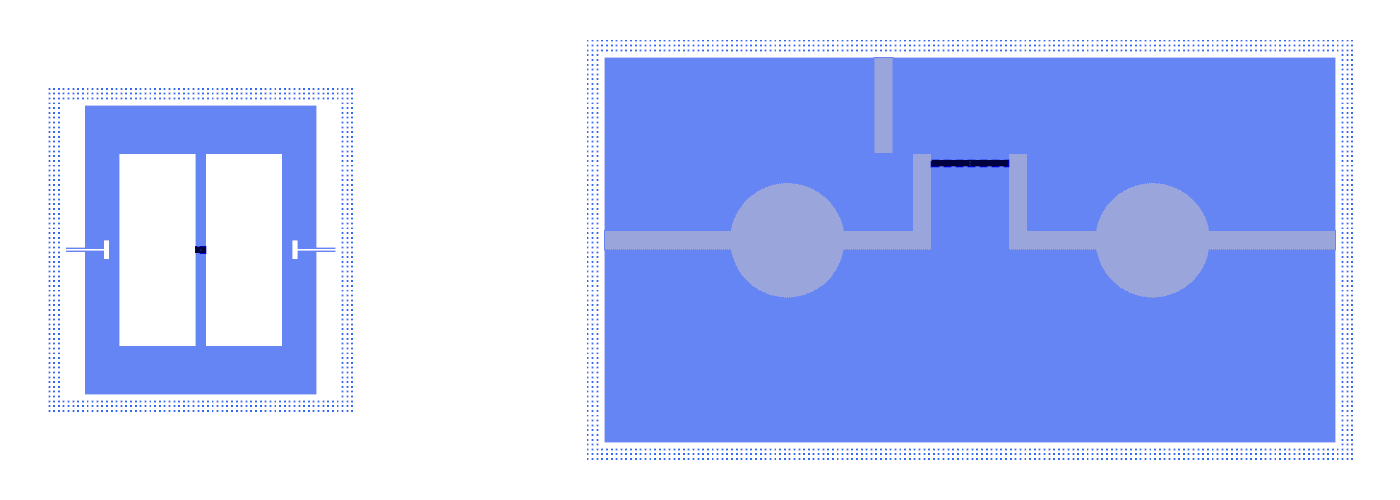

WindowsPath('examples/designs/metal/iswap2_pocket_tc_step_parts.png')

In [6]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
# flux-tunable qubits / couplers: a Quantcore SQUID of two junctions, R_n 45 kΩ in parallel (L_J 6.73 nH at zero
# flux, C_J 15 fF); SQ_PARAMS = {"junction_type": "Quantcore Squid", "junction_params": {"lj_nH": 6.73}}
SQ_PARAMS, SQUID = trilayer_junction("metal:TransmonCrossFL", lj_nH=JUNCTION["Lj_nH"], squid=True)
print("qubits:", JJ_PARAMS, JUNCTION, "| coupler:", SQ_PARAMS, SQUID)
with d.batch():
    pads = {"bus_03": {"loc_W": 0, "loc_H": -1, "pad_width": "100um", "pad_gap": "50um"},
            "readout": {"loc_W": 0, "loc_H": 1, "pad_width": "100um", "pad_gap": "50um"}}
    q = {n: d.add(n, "metal:TransmonPocket6", at=P(x, 0), rot=90, junction=JUNCTION, **JJ_PARAMS, pad_width="1mm",
                  pad_height="0.4mm", pocket_width="1.5mm", pocket_height="1.2mm", pad_gap="0.05mm",
                  connection_pads=pads)
         for n, x in (("Q1", -4000), ("Q2", 4000))}
    tc = d.add("TC", "metal:TunableCoupler02", at=P(0, 0), junction=SQUID, **SQ_PARAMS)
    # the pocket Metal never adds: pocket_height 2 mm, pin to pin (3.8 mm) wide, centred on the coupler
    d.add("TC_pocket", "metal:Rectangle", at=P(0, 0), width=3800, height=2000, subtract=True)
print("Q1 ports:", sorted(q["Q1"].ports), "| TC ports:", sorted(tc.ports))
snap(d, OUT / "iswap2_pocket_tc_step_parts.png", box=P(-5000, -1300) + P(2200, 1300), size=(1400, 500), width=560)

## 6 · Routes

All lines are 10 / 6 µm CPW on Metal's own corner points (`nodes`), so their paths and lengths are the tutorial's:
- **route1 / route2:** qubit ↔ coupler (Metal `RouteStraight`: 5 µm leads, a straight line across the 50 µm pin
  step);
- **route3:** the coupler's flux bias from `P3_C` (a long lead west, then down to the stub; fillet 90 µm);
- **route4 / route5:** the 10 mm meandered lines from each qubit's outer pad to its launchpad (Metal's
  `RouteMeander` corner points, 200 µm pitch, fillet 90 µm). The source's "readout" lines end galvanically on the
  pads: they are port lines, not resonators.

The pad rule moved the three launchpads outward, so the last segment of route3, route4 and route5 is longer than in
the source (printed lengths). The **sim group** `Q1_TC_Q2` names the FEM box: both qubits, the coupler with its
pocket and the two lines between them.

route lengths (µm): {'route1': 1400.9, 'route2': 1400.9, 'route3': 9084.5, 'route4': 11220.0, 'route5': 11220.0}


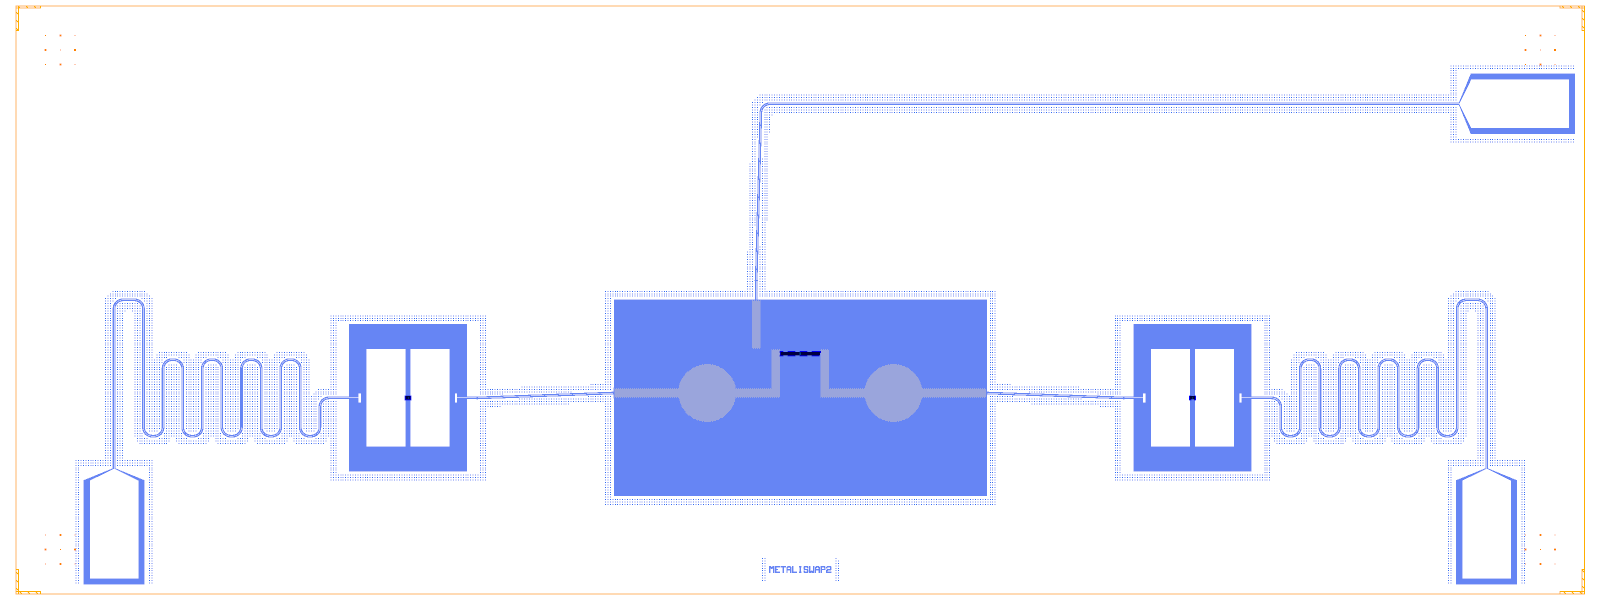

WindowsPath('examples/designs/metal/iswap2_pocket_tc_step_routes.png')

In [7]:
# Metal's corner points (µm, Metal frame) of the RouteMeander route4 (route5 is its mirror) and of route3
ROUTE4 = [[-4900.0, 0.0], [-4900.0, -389.51], [-5100.0, -389.51], [-5100.0, 389.51], [-5300.0, 389.51], [-5300.0, -389.51], [-5500.0, -389.51], [-5500.0, 389.51], [-5700.0, 389.51], [-5700.0, -389.51], [-5900.0, -389.51], [-5900.0, 389.51], [-6100.0, 389.51], [-6100.0, -389.51], [-6300.0, -389.51], [-6300.0, 389.51], [-6500.0, 389.51], [-6500.0, -389.51], [-6700.0, -389.51], [-6700.0, 1000.0], [-7000.0, 1000.0]]
ROUTE3 = [[-400.0, 3000.0], [-450.0, 1200.0]]
with d.batch():
    # qubit ↔ coupler (Metal RouteStraight: 5 µm leads, a straight line across the 50 µm pin step)
    d.route("route1", q["Q1"].bus_03, tc.pin2, r=1, nodes=PP([(-3295, 0), (-1905, 50)]), **CPW)
    d.route("route2", q["Q2"].readout, tc.pin1, r=1, nodes=PP([(3295, 0), (1905, 50)]), **CPW)
    # coupler flux bias (lead west, then down to the stub; fillet 90 µm)
    d.route("route3", lp["P3_C"].tie, tc.fbl, r=90, nodes=PP(ROUTE3), **CPW)
    # 10 mm meandered lines to the launchpads (Metal's corner points, fillet 90 µm)
    d.route("route4", q["Q1"].readout, lp["P1_C"].tie, r=90, nodes=PP(ROUTE4), **CPW)
    d.route("route5", q["Q2"].bus_03, lp["P2_C"].tie, r=90, nodes=PP([(-x, y) for x, y in ROUTE4]), **CPW)
# FEM box: both qubits, the coupler (with its pocket) and the two lines between them
d.sim_group("Q1_TC_Q2", ["Q1", "TC", "TC_pocket", "Q2", "route1", "route2"], margin_um=200, analyses=["q3d_cmatrix"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "iswap2_pocket_tc_step_routes.png", size=(1600, 600), width=560)

## 7 · Centring and save

The PDK wants the chip content centred in the die. Here the source's arrangement already fills its 16 × 6 mm box:
Q1 and Q2 sit symmetrically about the coupler at the box centre in x, and the circuit between the pads (the qubits,
the coupler and the lines, the flux line along the top) is centred in y as well. What is off-centre is the box of
*everything*, pads included: the pad rule put P1_C / P2_C on the south edge and P3_C on the east edge, so that box
leans south-east. `center_in_die` measures that box; a pad slides back to its edge after the shift, so a shift
here would only move the circuit off-centre and push P1_C and P3_C into the frame's corner marker areas. The cell
measures both offsets and tries `center_in_die` on a copy to show it (`frame_keepout` warnings); the design keeps
the source's placement. Then it is saved: the JSON is the deliverable.

In [8]:
from collections import Counter
from kqcircuits.pya_resolver import pya
from quantcore_circuits.assembly.sidecar import sidecar_dict
from _common import _pad_instances


def centre_offsets(d):
    """Content centre − die centre (µm): of everything placed, and of the circuit without the bond pads."""
    side, pads = sidecar_dict(rebuild(d), overlays=False), set(_pad_instances(d))
    x0, y0, x1, y1 = d.design.chip.box
    out = {}
    for label, skip in (("everything", set()), ("without the pads", pads)):
        box = pya.DBox()
        for n, inst in side["instances"].items():
            if inst.get("bbox") and n not in skip:
                box += pya.DBox(*inst["bbox"])
        for route in side["routes"].values():
            for x, y in route.get("polyline") or []:
                box += pya.DPoint(x, y)
        out[label] = (round(box.center().x - (x0 + x1) / 2), round(box.center().y - (y0 + y1) / 2))
    return out


print("content centre − die centre (µm):", centre_offsets(d))
DESIGN = d.save(OUT / "iswap2_pocket_tc.json")
trial = design_copy(DESIGN, "_centred")          # what center_in_die would do, on a copy
print("center_in_die on a copy: shift", center_in_die(trial), "µm →",
      dict(Counter(i.rule for i in (rebuild(trial) and trial.drc()).issues if i.rule == "frame_keepout")) or "no frame warnings")
TX, TY = d.data["instances"]["TC"]["place"]["at"]
P = lambda x, y: (TX + x, TY + y)                # Metal µm → Designer µm (TC is Metal's (0, 0))
print(d, "→", DESIGN)

content centre − die centre (µm): {'everything': (296, -296), 'without the pads': (0, 0)}


center_in_die on a copy: shift (-296.0, 296.0) µm → {'frame_keepout': 2}
<Designer iswap2_pocket_tc: 7 instances, 5 routes, live=False> → examples\designs\metal\iswap2_pocket_tc.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**; six `dangling_port` warnings (`squid_a` / `squid_b` of Q1, Q2 and TC: the junction
attachment points, drawn by the cells); one `overlap`, the coupler and its own pocket, by design. **No PDK design
warnings:** the three pads are at 100 µm (`pad_edge`), the nominal junctions are 45 kΩ and the coupler's PDK SQUID
(two 90 kΩ junctions) is 45 kΩ in parallel, inside the 40–50 kΩ window (`pdk_rn` checks the device), and there are no
targets (`pdk_fq`).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 7 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 6 | Q1.squid_a is not connected (no route or snap) |
| warning | `overlap` | 1 | TC and TC_pocket overlap |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+296, -296) µm |
| junction types | Quantcore Junction × 2, Quantcore Squid × 1 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: `TransmonPocket6` → two floating pads (`island1` / `island2`) with
the junction, a node per connection pad; `TunableCoupler02` on its pocket → two floating pads with the SQUID between
them and the bus (`pin1`–`pin2`) as one node coupled to both pads (rough; the drawn coupler is a series SQUID, see
step 10), the flux stub as a control. route1 / route2 join the qubits' inner pads to the bus; route4 / route5 are
lines from the outer pads to the 50 Ω launchpads (port lines, not resonators); route3 carries the coupler's flux
bias.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "TC."))})

**10 nodes · 29 branches · 1 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `Q1.readout` | `P1_C.pad`, `Q1.readout` |
| `Q2.bus_03` | `P2_C.pad`, `Q2.bus_03` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.bus_03` | `Q1.bus_03`, `Q2.readout`, `TC.bus` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `TC.island1` | `TC.island1` |
| `TC.island2` | `TC.island2` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P1_C` | R | `Q1.readout` – `gnd` | 50 Ω |
| `Port_P2_C` | R | `Q2.bus_03` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 175 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 175 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 94.6 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_bus_03` | C | `Q1.island2` – `Q1.bus_03` | 8.52 fF |
| `Cf_Q1_bus_03` | C | `Q1.island1` – `Q1.bus_03` | 0.89 fF |
| `Cc_Q1_bus_03` | C | `Q1.bus_03` – `gnd` | 42.9 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 8.52 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 0.89 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 42.9 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 175 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 175 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 94.6 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_bus_03` | C | `Q2.island2` – `Q2.bus_03` | 8.52 fF |
| `Cf_Q2_bus_03` | C | `Q2.island1` – `Q2.bus_03` | 0.89 fF |
| `Cc_Q2_bus_03` | C | `Q2.bus_03` – `gnd` | 42.9 fF |
| `Cg_Q2_readout` | C | `Q2.island1` – `Q1.bus_03` | 8.52 fF |
| `Cf_Q2_readout` | C | `Q2.island2` – `Q1.bus_03` | 0.89 fF |
| `Cc_Q2_readout` | C | `Q1.bus_03` – `gnd` | 42.9 fF |
| `C_TC_1` | C | `TC.island1` – `gnd` | 110 fF |
| `Cb_TC_1` | C | `TC.island1` – `Q1.bus_03` | 42 fF |
| `C_TC_2` | C | `TC.island2` – `gnd` | 110 fF |
| `Cb_TC_2` | C | `TC.island2` – `Q1.bus_03` | 42 fF |
| `C_TC_12` | C | `TC.island1` – `TC.island2` | 43 fF |
| `Cc_TC_bus` | C | `Q1.bus_03` – `gnd` | 160 fF |
| `J_TC` | SQUID | `TC.island1` – `TC.island2` | Lj 6.73 nH, Cj 15 fF |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `route3` | flux_bias | `J_TC` | `route3` | 9084 |

**Unconnected ports:** none

**Builder notes:**

- Port_P3_C: both ends on gnd after merging conductors (dropped)

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.bus_03': 'Q1.bus_03', 'Q1.readout': 'Q1.readout', 'TC.pin1': 'Q1.bus_03', 'TC.pin2': 'Q1.bus_03', 'TC.fbl': 'control:flux', 'TC.squid_a': 'TC.island1', 'TC.squid_b': 'TC.island2'}


## 10 · LOM simulation

Each qubit with its 10 mm line to the launchpad (κ to the port), the coupler alone, then Q1–TC–Q2 (static ZZ).

- Q1 / Q2: with the PDK junction ≈ 4.3 GHz (mm-scale pads; the assumed 10 nH gave 3.67 GHz), small anharmonicity,
  κ into the 50 Ω launchpad through the 10 mm line.
- TC alone: its SQUID mode at zero flux (≈ 5.3 GHz estimated).
- **Q1–TC–Q2: QuCat fails** (`KeyError: 'ComplexInfinity'`, printed below). The `TunableCoupler02` LOM model joins
  `pin1` and `pin2` into one bus node coupled equally to both floating pads: a balanced bridge, so the SQUID mode is
  exactly decoupled and the symbolic solve divides by zero. Drawn, the coupler is a SQUID *in series* in the line
  (`pin2` – left arm and pad – SQUID – right pad and arm – `pin1`, zoom in step 15), which is what the FEM job sees.
  Request for lom (a series-SQUID model); until then there is no coupled result.

In [11]:
single = simulate_groups(d, {"Q1+route4": ["Q1", "route4", "P1_C"], "Q2+route5": ["Q2", "route5", "P2_C"],
                             "TC": ["TC"]})
for g, r in single.items():
    display(Markdown(f"**{g}:**\n\n" + modes_md(r)))
display(Markdown(groups_md(single)))
try:   # fails with the current TunableCoupler02 model (see the markdown above; for lom)
    coupled = simulate_groups(d, {"Q1+TC+Q2": ["Q1", "route1", "TC", "route2", "Q2"]}, max_modes=3)
    display(Markdown("**Q1–TC–Q2, QuCat normal modes:**\n\n" + modes_md(coupled["Q1+TC+Q2"])))
    display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))
except Exception as e:
    print("Q1+TC+Q2: QuCat failed:", type(e).__name__, str(e)[:120])

**Q1+route4:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 4.3202 | 0.417 | 96.1 | J_Q1 1.00 |

**Q2+route5:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q2 | qubit | 4.3202 | 0.417 | 96.1 | J_Q2 1.00 |

**TC:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| TC | qubit | 5.2981 | 0 | 144.6 | J_TC 1.00 |

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+route4 | Q1 | 4.2218 | -101.5 | – | – | – | – |
| Q2+route5 | Q2 | 4.2218 | -101.5 | – | – | – | – |
| TC | TC | 5.1493 | -154.7 | – | – | – | – |

Q1+TC+Q2: QuCat failed: KeyError 'ComplexInfinity'


## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

One job: a **Q3D C-matrix** for both qubits, the coupler (with its pocket) and the two lines between them. It
replaces the LOM's pad and bus estimates by net name. Its nets name both qubits' islands and `TC.island1`; the
coupler's arms are part of the line nets (`Q1.bus_03`, `Q2.readout`), as drawn, so there is no `TC.island2` net
until the coupler model is a series SQUID.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN, ["Q1_TC_Q2"])
display(Markdown(jobs_md(jobs)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_TC_Q2 | `build/jobs/iswap2_pocket_tc_Q1_TC_Q2_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `TC.junction`<br>3 · junction · `Q2.junction`<br>4 · waveguide · `Q1.bus_03`<br>5 · waveguide · `TC.pin2`<br>6 · waveguide · `Q2.readout`<br>7 · waveguide · `TC.pin1`<br>8 · edge · `route3`<br>9 · edge · `route4`<br>10 · edge · `route5` | `Q1.island2`, `TC.island1`, `Q2.island2`, `Q1.bus_03`, `Q2.readout`, `route4`, `route5`, `Q1.island1`, `Q2.island1` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q1_TC_Q2'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {f"{g} · q3d": v for g, v in jobs.items()})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q1_TC_Q2 · q3d: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

Copy the saved design (`design_copy`: a non-live Designer that never writes over the JSON), change one property —
here Q1's pad height, 0.4 → 0.3 mm — and re-run the LOM of Q1 with its line. Smaller pads mean a smaller C_Σ: the
charging energy grows, so f_q and |α| go up; κ through the 10 mm line changes with the pad's coupling to it.

In [15]:
d2 = design_copy(DESIGN)
d2["Q1"].set(pad_height="0.3mm")                 # 0.4 → 0.3 mm
res2 = simulate_groups(d2, {"Q1+route4": ["Q1", "route4", "P1_C"]})
display(Markdown(params_delta_md({"Q1+route4": single["Q1+route4"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+route4: Q1.f_q_GHz` | 4.2218 | 4.4859 | +0.264 |
| `Q1+route4: Q1.alpha_MHz` | -101.48 | -115.36 | -13.88 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The iSWAP notebook never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\iswap2_pocket_tc.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 11798 |
| 2/0 | JJ_STRAIGHT | 3 |
| 3/0 | M3 | 11786 |
| 4/0 | JJ_BENT | 3 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 11782 holes on the mask.

→ `build/iswap2_pocket_tc_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's screenshot of Example 2); the coupler in its pocket; its SQUID; Q1 with its two
connection pads; the **fab mask** round the coupler (1/0 etch with the PDK cheese band, the 3/0 keep-out, the
junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions
are read from the design after the centring shift (`P` is relative to the coupler).

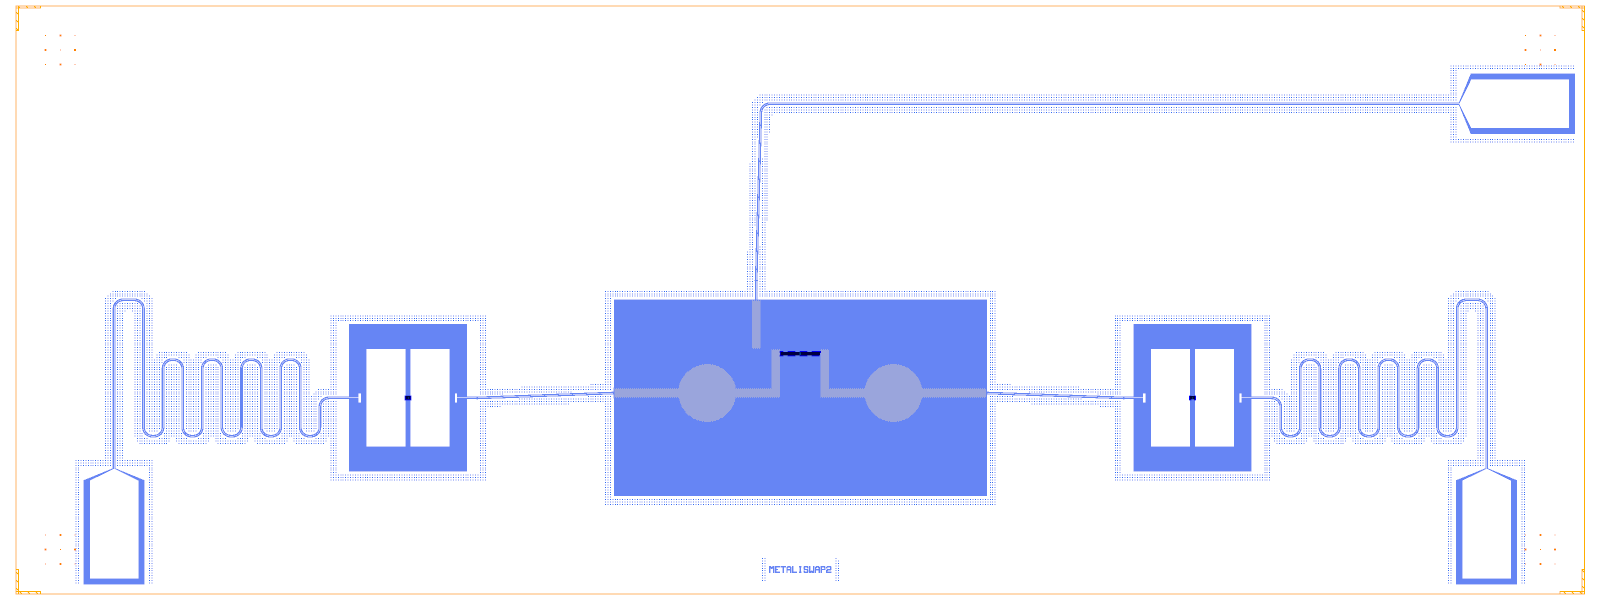

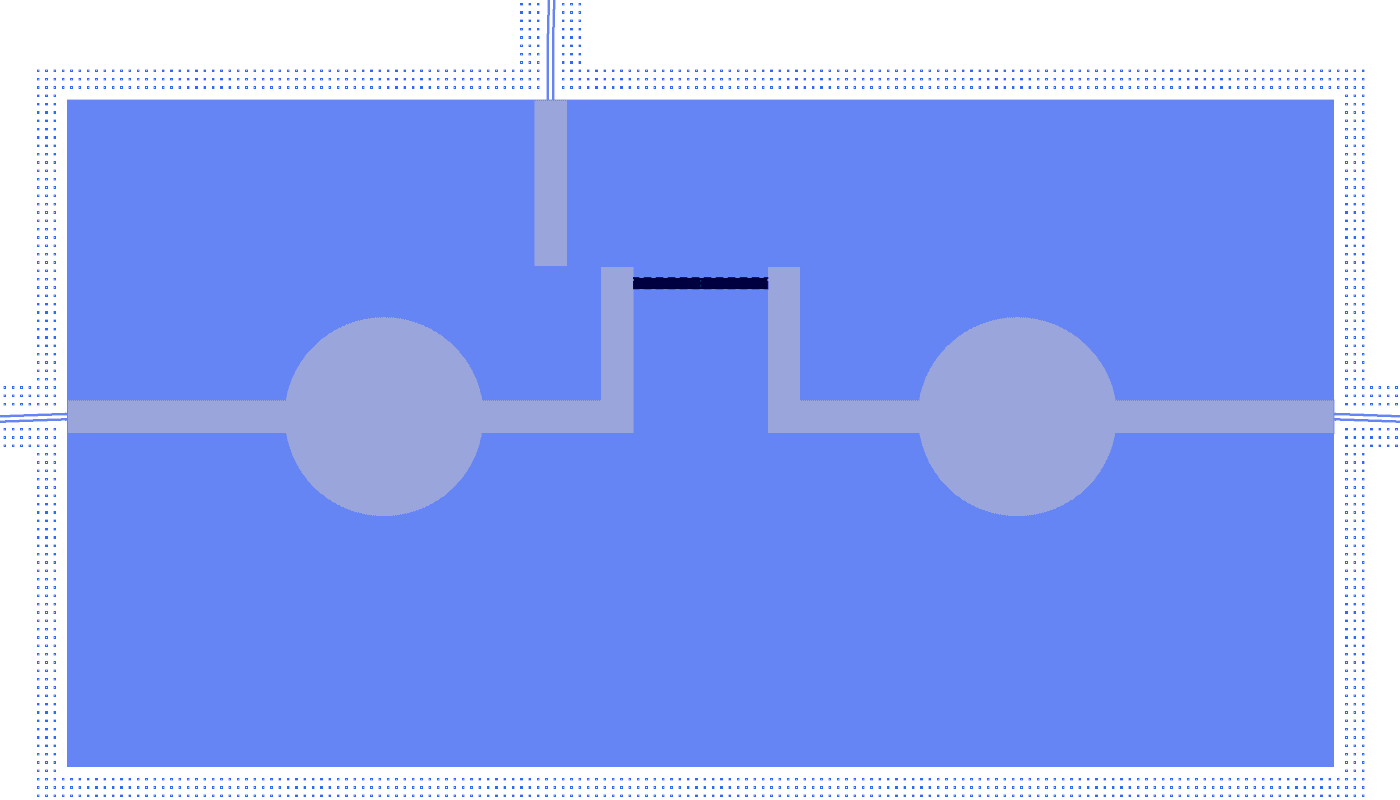

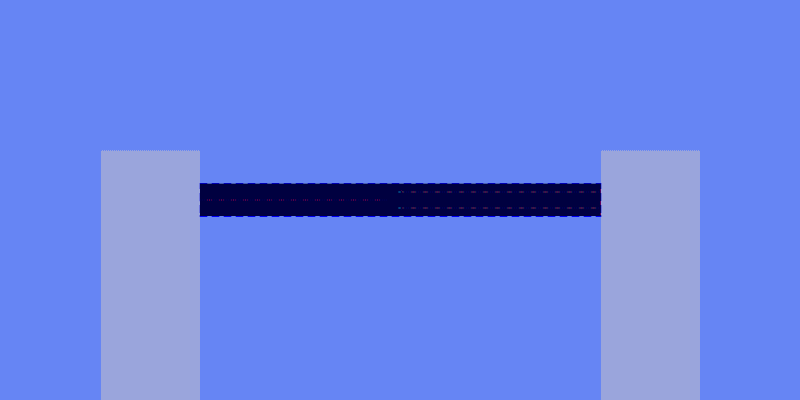

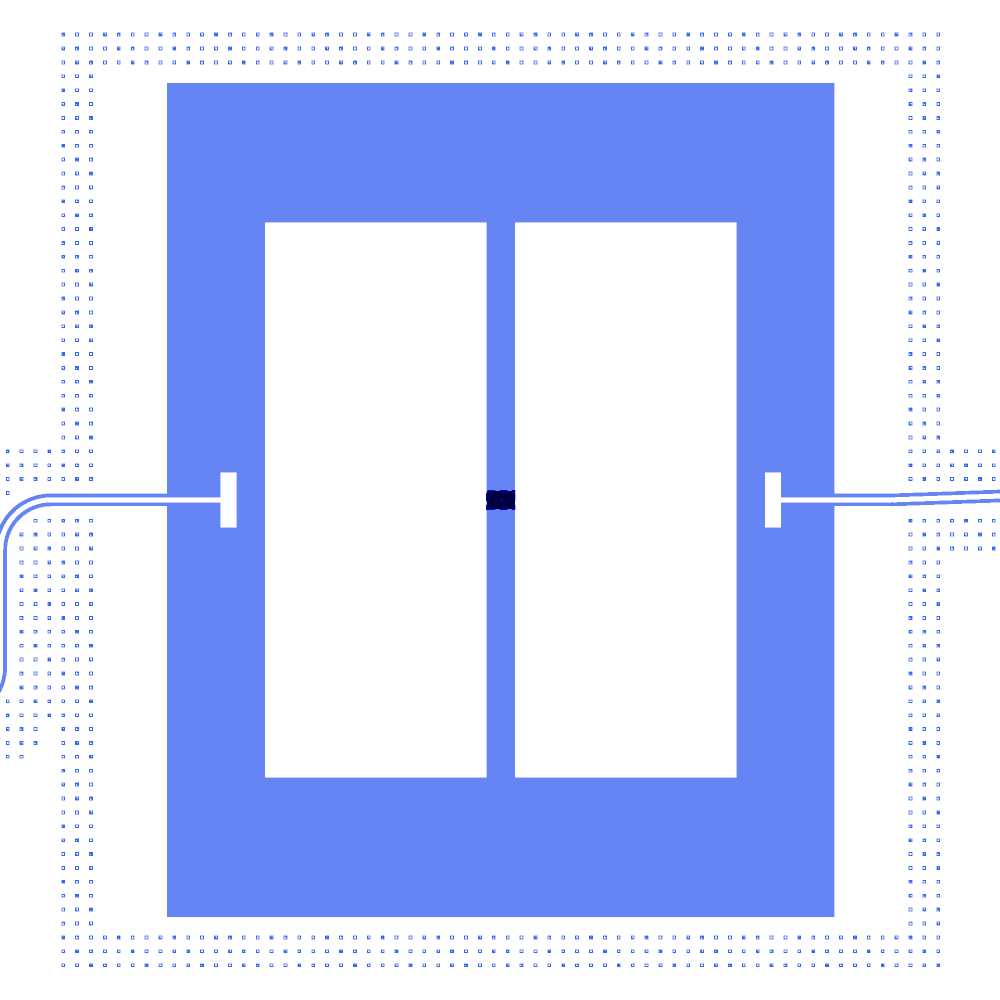

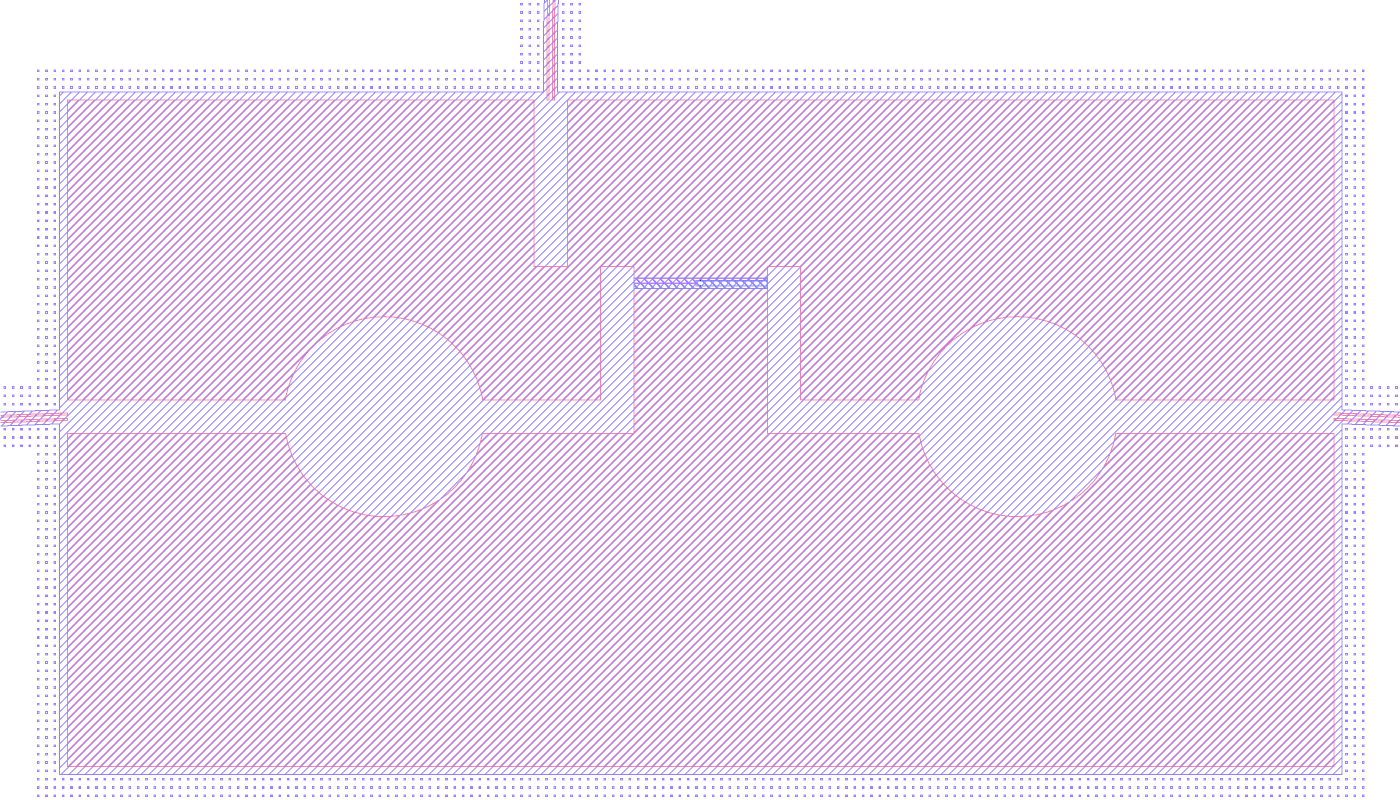

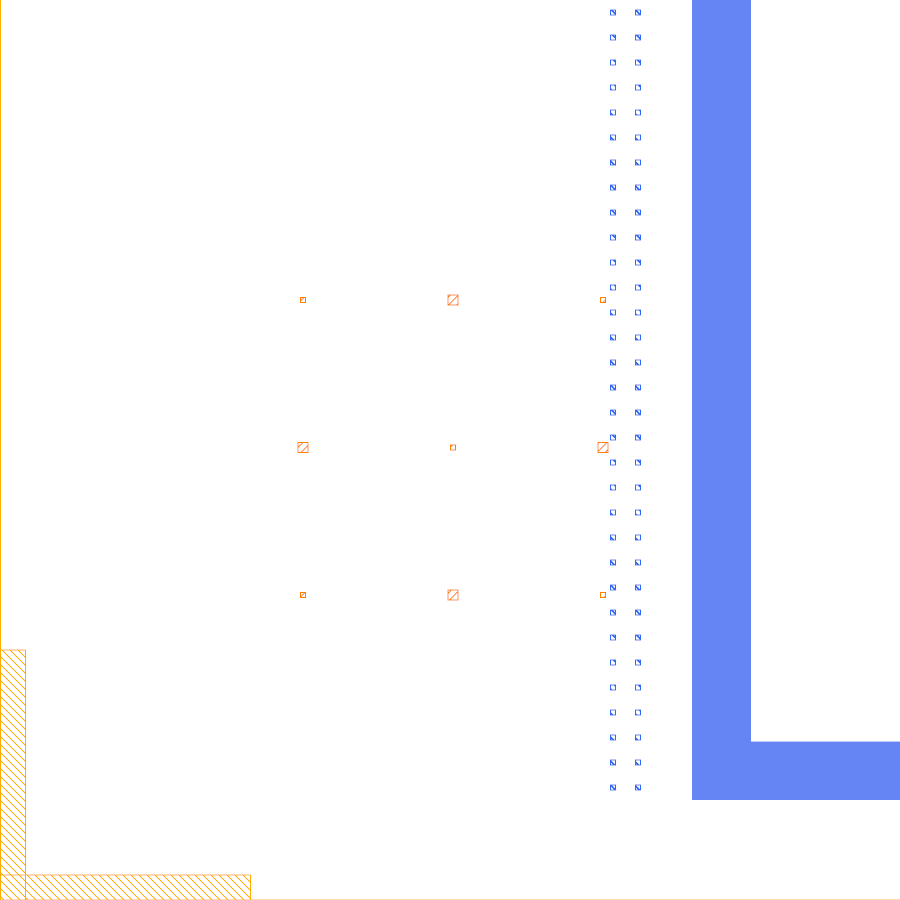

In [17]:
show_snapshot(d, OUT / "iswap2_pocket_tc.png", size=(1600, 600))
show_snapshot(d, OUT / "iswap2_pocket_tc_tc.png", box=P(-2100, -1100) + P(2100, 1300), size=(1400, 800), width=520)
show_snapshot(d, OUT / "iswap2_pocket_tc_jj.png", box=P(-400, 250) + P(400, 650), size=(800, 400), width=320)
show_snapshot(d, OUT / "iswap2_pocket_tc_q1.png", box=P(-4900, -900) + P(-3100, 900), size=(1000, 1000), width=400)
snap_file(Path("build") / "iswap2_pocket_tc_fab.oas", OUT / "iswap2_pocket_tc_cheese.png",
          box=P(-2100, -1100) + P(2100, 1300), size=(1400, 800), width=520)
show_snapshot(d, OUT / "iswap2_pocket_tc_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, every route's end pins and Metal corner points (route1 / route2 straight, route4 / route5 10 mm meanders), the sim group |
| PDK changes | QCT frame on the source's 16 × 6 mm box; sapphire stack; launchpads 100 µm from the south (P1_C, P2_C) and east (P3_C) edges (were 692 µm in); trilayer junctions (PDK nominal qubits, PDK SQUID coupler); PDK cheese band; the circuit between the pads stays centred (no shift: `center_in_die` would push P1_C / P3_C into the frame's marker areas, step 7) |
| differs | the coupler pocket is added (Metal never draws it); the pad leads of route3 / route4 / route5 are longer; f_q ≈ 4.3 GHz with the PDK junction (the assumed 10 nH gave 3.67 GHz) |
| PDK design warnings | none |
| open | the Q1–TC–Q2 LOM fails (series-SQUID coupler model missing, for lom); the FEM job is exported, not solved (`RUN_FEM = False`) |